In [1]:
import pandas as pd

In [2]:
# orders_qu.csv
url = "https://drive.google.com/file/d/1kvYPlqcaKuBpHStyaNSchBYIb2iTuEji/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
orders_qu = pd.read_csv(path)

# orderlines_qu.csv
url = "https://drive.google.com/file/d/1krfmZrcb92ZYPXu32fD6i6OA-_LQpVfo/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
orderlines_qu = pd.read_csv(path)

# products_cl.csv
url = "https://drive.google.com/file/d/1IPnKYLSnrST0HBZMeSeNrhFfWU31QvwB/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
products_cl = pd.read_csv(path)

# brands_cl.csv
url = "https://drive.google.com/file/d/1XGyabaa4mAkjixMk3XPgx_14OoSse3rs/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
brands_cl = pd.read_csv(path)

In [3]:
df = (orderlines_qu
      .merge(products_cl[["sku", "name", "price"]], on="sku", how="left")
      .merge(orders_qu[["order_id", "created_date", "total_paid"]],
             left_on="id_order", right_on="order_id", how="left"))

df["created_date"] = pd.to_datetime(df["created_date"])
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

df["rabatt_prozent"] = (df["price"] - df["unit_price"]) / df["price"] * 100
df["reduziert"] = df["rabatt_prozent"] > 1

print(df.shape)
df.head()

(53231, 14)


,id,id_order,product_id,product_quantity,sku,unit_price,date,name,price,order_id,created_date,total_paid,rabatt_prozent,reduziert
0,1119116,299545,0,1,OWC0100,47.49,2017-01-01 01:46:16,OWC In-line Digital Temperature Sensor Kit HDD...,60.99,299545,2017-01-01 01:51:47,51.48,22.134776,True
1,1119119,299546,0,1,IOT0014,18.99,2017-01-01 01:50:34,iOttie Easy View 2 Car Black Support,22.95,299546,2017-01-01 01:57:34,18.99,17.254902,True
2,1119120,295347,0,1,APP0700,72.19,2017-01-01 01:54:11,Apple 85W MagSafe 2 charger MacBook Pro screen...,89.00,295347,2017-01-01 02:02:38,72.19,18.887640,True
3,1119134,299556,0,1,CRU0039-A,60.90,2017-01-01 02:20:14,(Open) Crucial 240GB SSD 7mm BX200,76.99,299556,2017-01-01 02:30:08,65.89,20.898818,True
4,1119145,299561,0,1,PEB0015,142.49,2017-01-01 02:38:50,Pebble Smartwatch Time Steel Black,299.99,299561,2017-01-01 02:39:47,154.48,52.501750,True


In [4]:
# DataFrame als CSV-Datei speichern
# index=False verhindert, dass der Index als extra Spalte gespeichert wird
df.to_csv('df.csv', index=False)

In [5]:
from google.colab import files

# Datei auf den eigenen Rechner herunterladen
files.download('df.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Einleitung (ca. 30 Sekunden)

„Guten Tag zusammen, wir sind das Eniac Data Analytics Team. Eniac verkauft Apple-Zubehör und Technik online. Wir haben uns angesehen, wie stark Produkte rabattiert werden und ob sich das nach Produktart unterscheidet. Dafür haben wir über 53.000 Bestellpositionen ausgewertet. Mein Teil ist die Grundlage: Ich zeige, welche Produktkategorien es gibt und wie sich die Preise darin verteilen. Danach übernehmen meine Kollegen die Rabatte.“

Code: Kategorien bilden

/tmp/ipykernel_13033/1006240411.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='kategorie', order=order_count, palette='viridis')


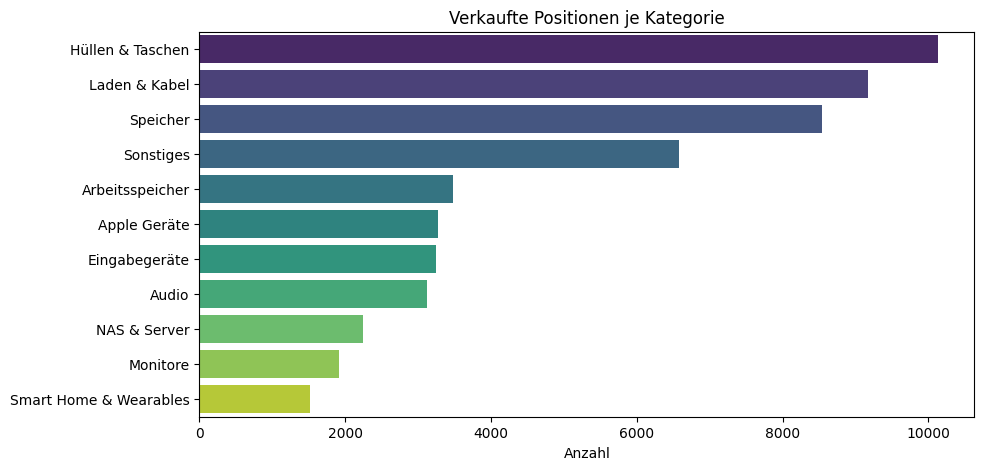

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('df.csv')

# Kategorien über Stichwörter im Produktnamen bilden
# Reihenfolge ist wichtig: "iPhone Case" soll bei Hüllen landen, nicht bei Geräten
# \b sorgt dafür, dass nur ganze Wörter gefunden werden ("pen" nicht in "Open")
kategorien = {
    'Hüllen & Taschen': r'\b(?:case|cover|protector|protection|sleeve|bag|backpack|folio|skin|shoulder|housing)\b',
    'Apple Geräte': r'^(?:open - |like new - |second hand - )?apple (?:iphone|ipad|macbook|imac|mac mini|ipod)',
    'NAS & Server': r'\b(?:nas|synology|qnap|ds\d+\w*|ts-\d+\w*)\b',
    'Arbeitsspeicher': r'\b(?:memory|ram)\b',
    'Speicher': r'\b(?:ssd|hdd|hard disk|hard drive|drive|flash|enclosure|raid|\d+tb|lacie|g-technology|sdhc|pendrive)\b',
    'Monitore': r'\b(?:monitor|display)\b',
    'Audio': r'\b(?:headphones?|headset|speaker|airpods|earphones?|beats|sonos|microphone|bose)\b',
    'Laden & Kabel': r'\b(?:chargers?|cable|adapter|hub|dock|battery|charging|usb-c|lightning)\b',
    'Eingabegeräte': r'\b(?:keyboard|mouse|trackpad|wacom|pen|keypad|pointer)\b',
    'Smart Home & Wearables': r'\b(?:hue|withings|netatmo|tado|eve|tile|pebble|smartwatch|thermostat\w*|trackr|fitbit)\b',
}

def get_category(name):
    name = name.lower()
    for kategorie, muster in kategorien.items():
        if pd.Series(name).str.contains(muster, regex=True)[0]:
            return kategorie
    return 'Sonstiges'

# nur einmal pro eindeutigem Produktnamen berechnen (schneller)
mapping = {name: get_category(name) for name in df['name'].unique()}
df['kategorie'] = df['name'].map(mapping)

# Grafik: Anzahl je Kategorie
order_count = df['kategorie'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='kategorie', order=order_count, palette='viridis')
plt.title('Verkaufte Positionen je Kategorie')
plt.xlabel('Anzahl')
plt.ylabel('')
plt.show()

Code: Preisverteilung je Kategorie

/tmp/ipykernel_13033/1404978041.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y='kategorie', x='price', order=order_price,


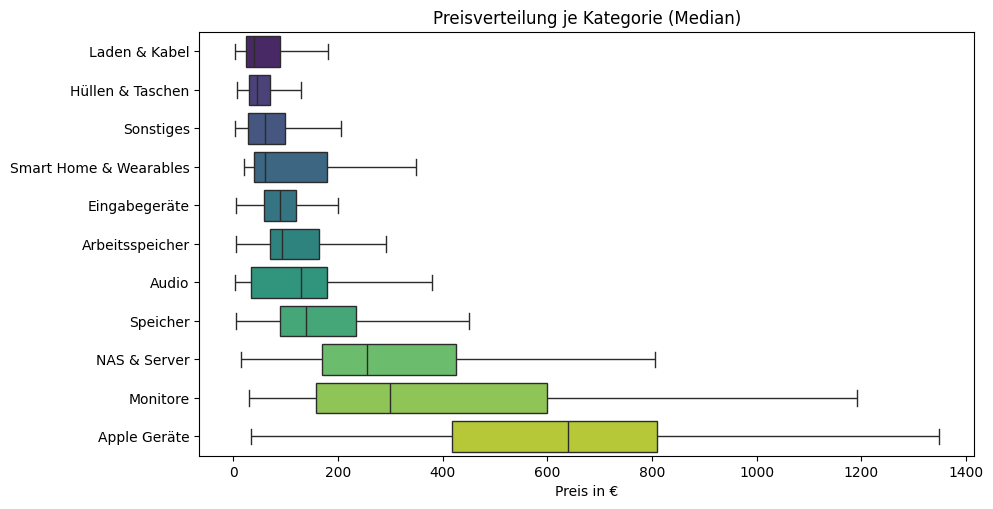

In [7]:
# Kategorien nach Median-Preis sortieren, damit die Grafik leicht lesbar ist
order_price = df.groupby('kategorie')['price'].median().sort_values().index

# Boxplot: Kasten = mittlere 50 %, Strich im Kasten = Median
# showfliers=False blendet extreme Ausreißer aus, sonst wird die Grafik unleserlich
plt.figure(figsize=(10, 5.5))
sns.boxplot(data=df, y='kategorie', x='price', order=order_price,
            showfliers=False, palette='viridis')
plt.title('Preisverteilung je Kategorie (Median)')
plt.xlabel('Preis in €')
plt.ylabel('')
plt.show()

Antworten für die zwei Fragen (je ca. 20 Sekunden)

Frage 1: Kategorien bilden
„Wir haben die Produktnamen nach Stichwörtern in 10 Kategorien eingeteilt, zum Beispiel Hüllen, Speicher oder Monitore. Der Rest landet in ‚Sonstiges‘. Die größten Kategorien sind Hüllen & Taschen (ca. 10.100 Positionen), Laden & Kabel (ca. 9.200) und Speicher (ca. 8.500).“

Frage 2: Preisverteilung
„Die Preise unterscheiden sich stark. Laden & Kabel und Hüllen liegen im Median bei etwa 40 bis 45 €. Apple Geräte liegen bei etwa 640 €, Monitore bei 300 € und NAS bei 255 €. Je teurer die Kategorie, desto breiter streuen die Preise.“

Hinweise
Eingeteilt wurde nach Stichwörtern, daher ist die Zuordnung nicht perfekt. Etwa 12 % der Positionen sind „Sonstiges“. Falls jemand fragt, kannst du das offen sagen.
Der Boxplot blendet Ausreißer aus. Das solltest du ebenfalls erwähnen können.
Bei „Apple Geräte“ sind nur Originalgeräte von Apple gezählt (iPhone, iPad, MacBook usw.), Zubehör dafür steckt in den anderen Kategorien.

In [8]:
# Feste Farben je Kategorie: Apple in Rot, alle anderen in Blau (dunkel = teuer, hell = günstig)
farben = {
    'Apple Geräte':           '#D7263D',  # Rot          (Median ca. 640 €)
    'Monitore':               '#0B2A5B',  # Dunkelblau   (ca. 300 €)
    'NAS & Server':           '#123F7D',  #              (ca. 255 €)
    'Speicher':               '#1A5799',  #              (ca. 140 €)
    'Audio':                  '#2B6FB0',  #              (ca. 130 €)
    'Arbeitsspeicher':        '#4A89C3',  #              (ca. 94 €)
    'Eingabegeräte':          '#6CA2D2',  #              (ca. 89 €)
    'Smart Home & Wearables': '#8FBADF',  #              (ca. 60 €)
    'Sonstiges':              '#A9CAE5',  #              (ca. 60 €)
    'Hüllen & Taschen':       '#C2D9EC',  #              (ca. 45 €)
    'Laden & Kabel':          '#D8E7F4',  # Hellblau     (ca. 40 €)
}

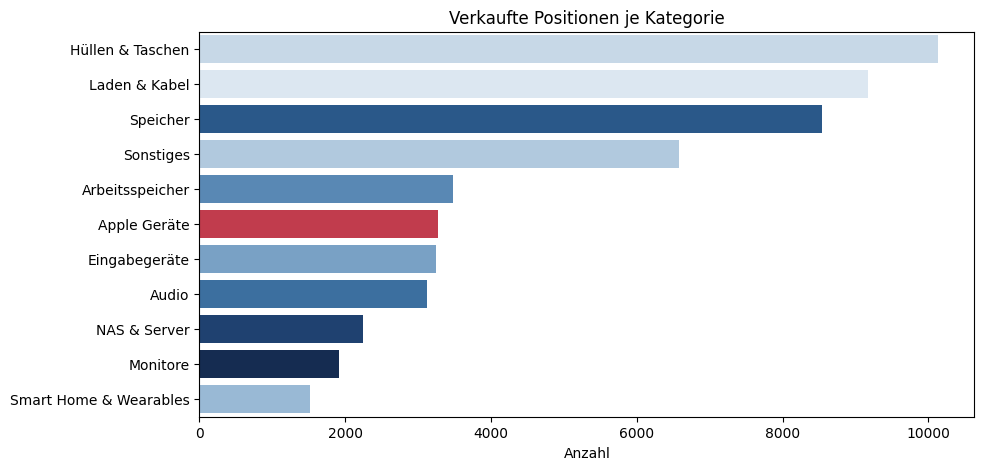

In [9]:
order_count = df['kategorie'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y='kategorie', order=order_count,
              hue='kategorie', palette=farben, legend=False)
plt.title('Verkaufte Positionen je Kategorie')
plt.xlabel('Anzahl')
plt.ylabel('')
plt.show()

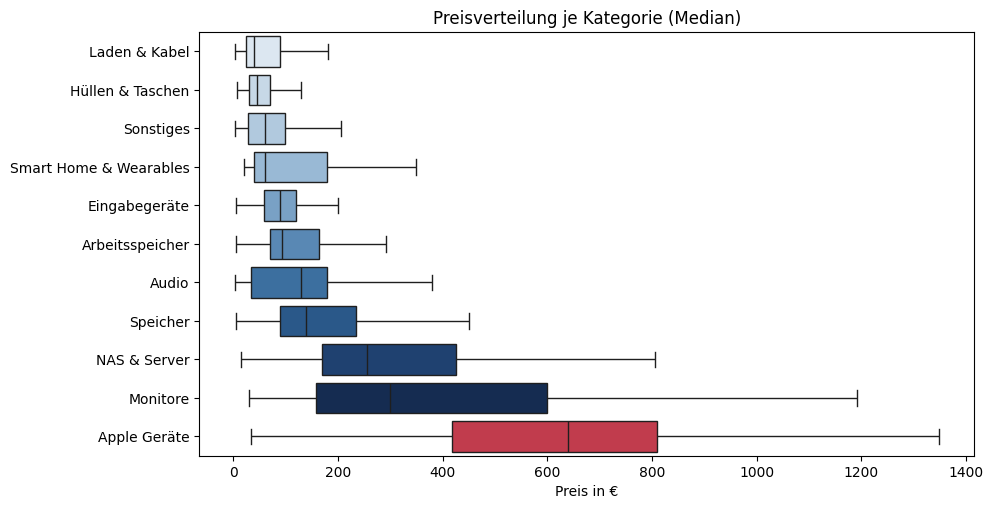

In [10]:
order_price = df.groupby('kategorie')['price'].median().sort_values().index
plt.figure(figsize=(10, 5.5))
sns.boxplot(data=df, y='kategorie', x='price', order=order_price,
            hue='kategorie', palette=farben, legend=False, showfliers=False)
plt.title('Preisverteilung je Kategorie (Median)')
plt.xlabel('Preis in €')
plt.ylabel('')
plt.show()

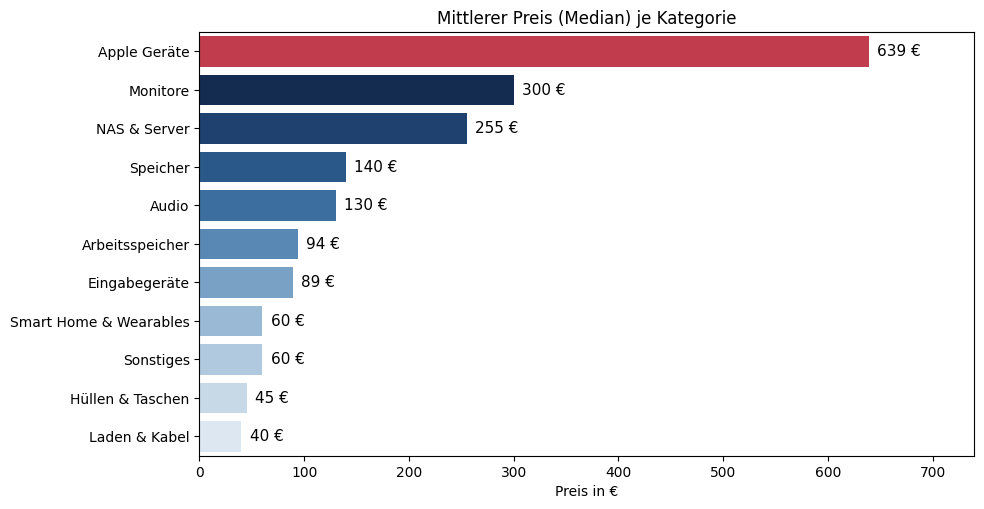

In [11]:
# Eine Zeile pro Kategorie mit dem mittleren Preis (Median), teuerste zuerst
medians = df.groupby('kategorie')['price'].median().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(data=medians, y='kategorie', x='price',
                 hue='kategorie', palette=farben, legend=False)

# Wert direkt an jeden Balken schreiben
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f €', padding=6, fontsize=11)

plt.title('Mittlerer Preis (Median) je Kategorie')
plt.xlabel('Preis in €')
plt.ylabel('')
plt.xlim(0, 740)   # etwas Platz rechts für die Beschriftung
plt.show()